<h1>Оценка эффективности системы рекомендаций онлайн-магазина здорового питания</h1>
<p>У магазина есть приложение, внутри которого реализована рекомендательная система: она подсказывает пользователю, какие товары ему может быть интересно добавить в корзину. Раньше система была реализована довольно прямолинейно: пользователю предлагалось добавить те товары, которые он часто покупал в прошлом.</p>
<p>Однако был разработан новый алгоритм, который теперь работает на основе ИИ и предлагает в том числе и те товары, которые раньше пользователь не покупал</p>
<p>Вопрос: <b>действительно ли новый алгоритм работает лучше, чем существующий?</b></p>
<p>Чтобы ответить на него, был проведен A/B-тест, в ходе которого контрольная группа пользователей продолжала пользоваться старой версией системы рекомендаций, а экспериментальная группа использовала новый алгоритм. <b>Период проведения A/B-теста — с 01.10.2023 по 14.10.2023 включительно</b>.</p>

<h1>Данные</h1>
<p>Таблица <b>user</b> (Общая информация о пользователях магазина)</p>
<ul>
    <li>id (int) - идентификатор</li>
    <li>gender (str) - пол</li>
    <li>age (int) - возраст на момент 01.09.2023</li>
    <li>region (str) - регион, в котором проживает пользователь</li>
</ul>
<p></p>
<p></p>
<p>Таблица <b>user_ab_group</b> (Информация о том, в какую группу в рамках эксперимента входил тот или иной пользователь. В эксперименте участвовали не все пользователи)</p>
<ul>
    <li>user_id  (int) - идентификатор</li>
    <li>group  (str) - - группа, в которую входит пользователь (control/treatment)
</li>
</ul>

<p>Таблица <b>user_purchase</b> (Информация о покупках, которые совершали пользователи. Также в таблице содержаться данные о покупках тех же пользователей вне A/B-эксперимента)</p>
<ul>
    <li>id (int) - идентификатор покупки</li>
    <li>user_id  (int) - идентификатор пользователя, который совершил покупку</li>
    <li>date_time  (str) - момент времени, когда была совершена покупка. Формат: “%Y-%m-%d %H:%M:%S“</li>
</ul>

<p>Таблица <b>purchase_good</b> (Информация о товарах, которые входили в список покупок, совершенных пользователями. Каждому товару из конкретной покупки соответствует отдельная строчка в таблице)</p>
<ul>
    <li>purchase_id  (int) - идентификатор покупки</li>
    <li>good_id (int) - идентификатор товара, который входит в эту покупку</li>
    <li>amount (int) - кол-во единиц товара, входящих в покупку</li>
    <li>was_in_recommended_goods (bool) - был ли приобретенный продукт добавлен в корзину по рекомендации</li>
</ul>

<p>Таблица <b>good</b> (Информация о товарах, которые продаются в магазине)</p>
<ul>
    <li>id  (int) - идентификатор покупки</li>
    <li>good_name (string) - идентификатор товара, который входит в эту покупку</li>
    <li>price_per_unit (int) - кол-во единиц товара, входящих в покупку</li>
</ul>

In [58]:
# импорт библиотек
import random
import pandas as pd
import seaborn as sns

from math import floor

In [59]:
# чтение данных
user = pd.read_csv("data/user.csv")
user_ab_group = pd.read_csv("data/user_ab_group.csv")
good = pd.read_csv("data/good.csv")
user_purchase = pd.read_csv("data/user_purchase.csv")
purchase_good = pd.read_csv("data/purchase_good.csv")

In [60]:
user.head()

,user_id,gender,age,region
0,1,Ж,23,Краснодарский край
1,2,Ж,43,Краснодарский край
2,3,М,36,Краснодарский край
3,4,Ж,39,Краснодарский край
4,5,М,43,Иркутская область


In [61]:
user_ab_group.head()

,user_id,group
0,5034,treatment
1,4725,treatment
2,911,treatment
3,13267,control
4,5636,control


In [62]:
good.head()

,id,good_name,price_per_unit
0,1,Органический авокадо,336
1,2,Льняные семена,796
2,3,Кокосовое масло Extra Virgin,558
3,4,Гречка цельнозерновая,484
4,5,Лосось дикого копчения,480


In [63]:
user_purchase.head()

,id,user_id,date_time
0,1,5784,2023-09-20 00:01:07
1,2,4468,2023-09-20 00:04:18
2,3,3827,2023-09-20 00:04:35
3,4,3272,2023-09-20 00:06:32
4,5,9461,2023-09-20 00:08:24


In [64]:
purchase_good.head()

,purchase_id,good_id,amount,was_in_recommended_goods
0,15495,34,2,False
1,42640,48,1,False
2,42640,36,1,False
3,42640,12,2,True
4,42640,35,1,True


<h2>Обработка данных</h2>

<h4>Проверка типов данных</h4>

In [65]:
user.dtypes

user_id    int64
gender       str
age        int64
region       str
dtype: object

In [66]:
user_ab_group.dtypes

user_id    int64
group        str
dtype: object

In [67]:
good.dtypes

id                int64
good_name           str
price_per_unit    int64
dtype: object

In [68]:
user_purchase.dtypes

id           int64
user_id      int64
date_time      str
dtype: object

In [69]:
user_purchase['date_time'] = pd.to_datetime(user_purchase['date_time'],
                                           format='%Y-%m-%d %H:%M:%S')

In [70]:
user_purchase.dtypes

id                    int64
user_id               int64
date_time    datetime64[us]
dtype: object

<h4>Предварительный анализ</h4>

<h5>Таблица <b>user</b></h5>

In [71]:
user['gender'].value_counts(normalize=True)

gender
Ж    0.509067
М    0.490933
Name: proportion, dtype: float64

In [72]:
user['region'].value_counts(normalize=True)

region
Краснодарский край       0.311600
Санкт-Петербург          0.231600
Иркутская область        0.148133
Нижегородская область    0.135733
Оренбургская область     0.103933
Астраханская область     0.049000
Республика Адыгея        0.020000
Name: proportion, dtype: float64

<Axes: xlabel='age', ylabel='Count'>

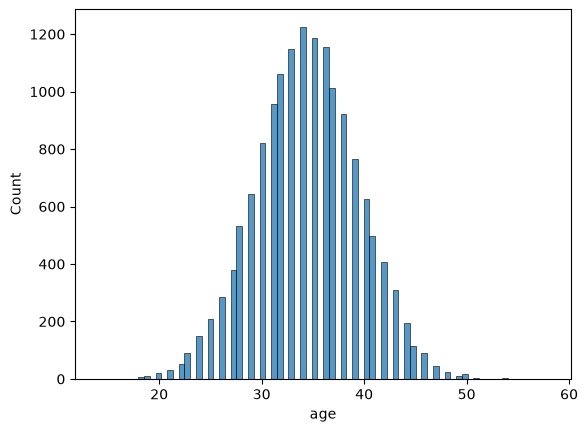

In [73]:
sns.histplot(user['age'])

In [74]:
user.describe()

,user_id,age
count,15000.000000,15000.000000
mean,7500.500000,34.429400
std,4330.271354,5.001122
min,1.000000,14.000000
25%,3750.750000,31.000000
50%,7500.500000,34.000000
75%,11250.250000,38.000000
max,15000.000000,58.000000


<p><b>Выводы</b></p>
<ul>
    <li>Среди пользователей примерно одинаковое кол-во мужчин и женщин</li>
    <li>Наибольшее число пользователей живут в Краснодарском крае</li>
    <li>Средний возраст пользователей - 34 года</li>
</ul>

<h5>Таблица <b>good</b></h5>

In [75]:
good.head()

,id,good_name,price_per_unit
0,1,Органический авокадо,336
1,2,Льняные семена,796
2,3,Кокосовое масло Extra Virgin,558
3,4,Гречка цельнозерновая,484
4,5,Лосось дикого копчения,480


In [76]:
good.describe()

,id,price_per_unit
count,100.000000,100.000000
mean,50.500000,508.860000
std,29.011492,99.104987
min,1.000000,299.000000
25%,25.750000,440.000000
50%,50.500000,496.000000
75%,75.250000,577.250000
max,100.000000,796.000000


In [77]:
good['good_name'].sort_values(ascending=True).unique()

<StringArray>
[                                        'Авокадо-масло',
                                       'Агавовый нектар',
                                     'Алоэ вера напиток',
                                    'Амарантовые хлопья',
                                        'Ананас сушёный',
                          'Арахисовая паста без добавок',
                                          'Белок гороха',
                                   'Белый чай в листьях',
                                         'Бобовые чипсы',
                                             'Бобы мунг',
                                     'Бразильские орехи',
                                       'Брокколи свежий',
                                             'Бурый рис',
                                       'Горчичное масло',
 'Горькая шоколадная плитка с высоким содержанием какао',
                            'Горький миндальный шоколад',
                            'Гранатовый сок натуральный',


In [78]:
good[(good['good_name'] == 'Авокадо-масло') | (good['good_name'] == 'Масло авокадо')]

,id,good_name,price_per_unit
76,77,Масло авокадо,548
90,91,Авокадо-масло,550


<p><b>Выводы</b></p>
<ul>
    <li>В списке товаров есть повторяющиеся позиции (Масло авокадо и Авокадо-масло)</li>
</ul>
<p><b>Гипотеза:</b> сначала товар назывался "масло авокадо", потом его переименовали</p>

In [79]:
a = purchase_good.merge(user_purchase, left_on='purchase_id', right_on='id')
b = a.merge(good, left_on='good_id', right_on='id')

In [80]:
b[(b['good_name'] == 'Авокадо-масло') | (b['good_name'] == 'Масло авокадо')] \
    .sort_values('date_time', ascending=True).tail()

,purchase_id,good_id,amount,was_in_recommended_goods,id_x,user_id,date_time,id_y,good_name,price_per_unit
61307,74923,91,1,False,74923,2589,2023-11-28 23:22:36,91,Авокадо-масло,550
155828,74926,91,1,False,74926,6622,2023-11-28 23:26:58,91,Авокадо-масло,550
155832,74926,77,1,False,74926,6622,2023-11-28 23:26:58,77,Масло авокадо,548
327150,74936,91,1,False,74936,13917,2023-11-28 23:38:41,91,Авокадо-масло,550
60586,74944,91,1,True,74944,2563,2023-11-28 23:49:39,91,Авокадо-масло,550


<p><b>Вывод:</b> гипотеза не подтвердилась, потому что оба товара покупались в том числе и в одинаковый день. Скорее всего, это сбой программы.</p>

<h5>Таблица <b>user_purchase</b></h5>

In [81]:
user_purchase.head()

,id,user_id,date_time
0,1,5784,2023-09-20 00:01:07
1,2,4468,2023-09-20 00:04:18
2,3,3827,2023-09-20 00:04:35
3,4,3272,2023-09-20 00:06:32
4,5,9461,2023-09-20 00:08:24


<Axes: xlabel='date_time', ylabel='Count'>

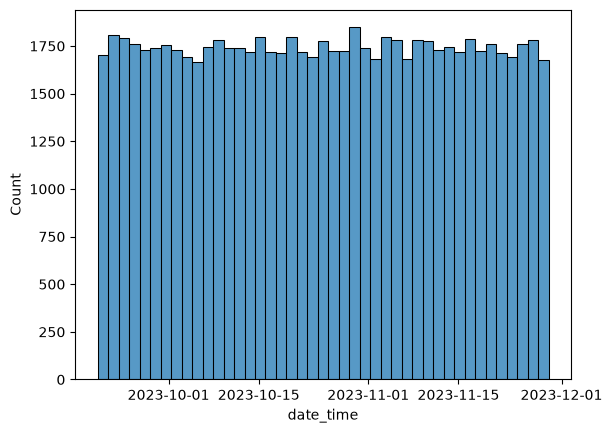

In [82]:
sns.histplot(user_purchase['date_time'])

<p><b>Выводы:</b> на графике видно, что нет аномальных скачков вверх или вниз, что говорит о независимости числа продаж от даты</p>

## Анализ результатов A/B-теста

<h4>Проверка разбиения пользователей на группы</h4>

In [83]:
user_purchase.groupby('user_id', as_index=False) \
            .agg({'date_time': 'count'})

,user_id,date_time
0,1,4
1,2,6
2,3,4
3,4,6
4,5,7
...,...,...
14982,14996,5
14983,14997,6
14984,14998,4
14985,14999,6


In [84]:
user_ab_group.head()

,user_id,group
0,5034,treatment
1,4725,treatment
2,911,treatment
3,13267,control
4,5636,control


In [85]:
control_group = set(user_ab_group[user_ab_group['group'] == 'control']['user_id'])
treatment_group = set(user_ab_group[user_ab_group['group'] == 'treatment']['user_id'])

In [86]:
# нет ли людей, которые попали в обе группы
control_group & treatment_group

set()

In [87]:
user_ab_group['group'].value_counts(normalize=True)

group
treatment    0.502728
control      0.497272
Name: proportion, dtype: float64

<p>Сделаем проверку на наличие ошибки <b>Sample Ratio Mismatch (SRM)</b> - равновероятно ли пользователи распределяются в группы?</p>

<p>Насколько вероятно наблюдать такое же различие при разбиении на группы?</p>

In [88]:
our_diff = len(treatment_group) - len(control_group)
our_diff

65

In [89]:
diffs = []

for i in range(10_000):
    arr = [random.randint(0, 1) for _ in range(len(user_ab_group))]
    # 0 - экспериментальная
    # 1 - контрольная
    diff = sum(arr) - (len(arr) - sum(arr)) # различие кол-ва пользователей в группах
    diffs.append(diff)

In [90]:
diffs_s = pd.Series(diffs)
diffs_s

0      -169
1        13
2        23
3        31
4       -47
       ... 
9995    105
9996    -55
9997     39
9998     -9
9999     -1
Length: 10000, dtype: int64

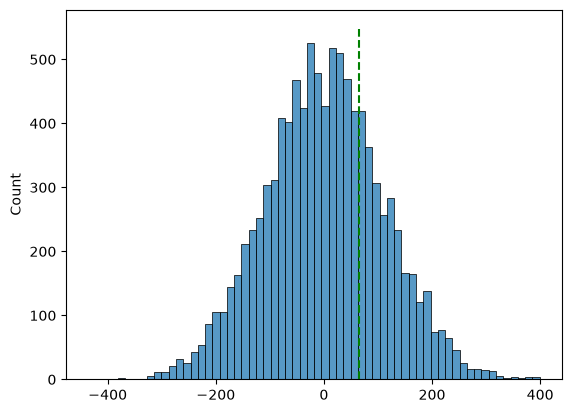

In [91]:
ax = sns.histplot(diffs_s)
ax.vlines([our_diff], 0, 550, linestyles='dashed', color='green')

In [92]:
alpha = 0.05
half_alpha = floor(len(diffs_s) * alpha / 2)
diffs_cut = sorted(diffs_s)[half_alpha:-half_alpha]

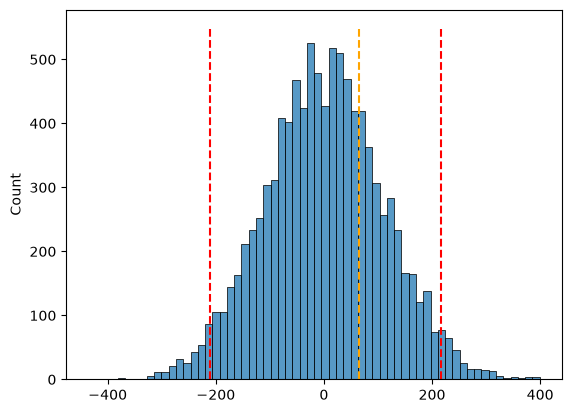

In [93]:
ax = sns.histplot(diffs_s)

ax.vlines([our_diff], 0, 550, linestyles='dashed', color='orange')
ax.vlines([diffs_cut[0], diffs_cut[-1]], 0, 550, linestyles='dashed', color='red')

<p>Значение не попало в критические области, следовательно, ошибка SRM отсутствует и разбиение на группы прошло должным образом</p>

#### Расчет метрики

Доля пользователей, у которых за период была хотя бы одна покупка с рекомендованным товаром

In [94]:
user

,user_id,gender,age,region
0,1,Ж,23,Краснодарский край
1,2,Ж,43,Краснодарский край
2,3,М,36,Краснодарский край
3,4,Ж,39,Краснодарский край
4,5,М,43,Иркутская область
...,...,...,...,...
14995,14996,М,41,Нижегородская область
14996,14997,Ж,30,Астраханская область
14997,14998,М,26,Краснодарский край
14998,14999,М,36,Оренбургская область


In [95]:
user_ab_group.sort_values('user_id', ascending=True)

,user_id,group
1792,1,control
2779,2,treatment
1400,4,control
6725,6,treatment
3961,9,control
...,...,...
6666,14995,control
8897,14996,treatment
6667,14998,treatment
7913,14999,control


In [96]:
# user + user_ab_group
t1 = pd.merge(user, user_ab_group, left_on='user_id', right_on='user_id')

#t1 + user_purchase
t2 = pd.merge(t1, user_purchase, left_on='user_id', right_on='user_id') \
        .rename(columns={'id':'purchase_id'})

#t2 + purchase_good
t3 = pd.merge(t2, purchase_good, left_on='purchase_id', right_on='purchase_id') \
        .sort_values(['user_id', 'purchase_id', 'good_id'])

In [97]:
t1

,user_id,gender,age,region,group
0,1,Ж,23,Краснодарский край,control
1,2,Ж,43,Краснодарский край,treatment
2,4,Ж,39,Краснодарский край,control
3,6,Ж,37,Санкт-Петербург,treatment
4,9,М,38,Оренбургская область,control
...,...,...,...,...,...
11910,14995,Ж,40,Астраханская область,control
11911,14996,М,41,Нижегородская область,treatment
11912,14998,М,26,Краснодарский край,treatment
11913,14999,М,36,Оренбургская область,control


In [98]:
t2

,user_id,gender,age,region,group,purchase_id,date_time
0,1,Ж,23,Краснодарский край,control,15495,2023-10-04 10:11:52
1,1,Ж,23,Краснодарский край,control,42640,2023-10-29 20:22:25
2,1,Ж,23,Краснодарский край,control,66123,2023-11-20 16:04:16
3,1,Ж,23,Краснодарский край,control,70221,2023-11-24 14:05:39
4,2,Ж,43,Краснодарский край,treatment,4093,2023-09-23 18:45:40
...,...,...,...,...,...,...,...
59571,15000,Ж,34,Республика Адыгея,treatment,33968,2023-10-21 17:27:03
59572,15000,Ж,34,Республика Адыгея,treatment,40198,2023-10-27 14:36:19
59573,15000,Ж,34,Республика Адыгея,treatment,50643,2023-11-06 05:23:23
59574,15000,Ж,34,Республика Адыгея,treatment,53057,2023-11-08 12:29:51


In [99]:
ab_result_table = t3[(t3['date_time'] >= '2023-10-01') & (t3['date_time'] <= '2023-10-14')]

In [100]:
ab_result_table

,user_id,gender,age,region,group,purchase_id,date_time,good_id,amount,was_in_recommended_goods
0,1,Ж,23,Краснодарский край,control,15495,2023-10-04 10:11:52,34,2,False
11,2,Ж,43,Краснодарский край,treatment,20107,2023-10-08 19:23:44,6,1,True
14,2,Ж,43,Краснодарский край,treatment,20107,2023-10-08 19:23:44,10,2,True
21,2,Ж,43,Краснодарский край,treatment,20107,2023-10-08 19:23:44,11,1,True
12,2,Ж,43,Краснодарский край,treatment,20107,2023-10-08 19:23:44,17,1,False
...,...,...,...,...,...,...,...,...,...,...
284340,15000,Ж,34,Республика Адыгея,treatment,21577,2023-10-10 04:14:11,37,1,True
284347,15000,Ж,34,Республика Адыгея,treatment,21577,2023-10-10 04:14:11,49,1,True
284345,15000,Ж,34,Республика Адыгея,treatment,21577,2023-10-10 04:14:11,64,1,False
284343,15000,Ж,34,Республика Адыгея,treatment,21577,2023-10-10 04:14:11,66,1,True


In [114]:
ab_result_table['user_id'].unique()
treatment_group = ab_result_table[ab_result_table['group'] == 'treatment']['user_id'].unique()
control_group = ab_result_table[ab_result_table['group'] == 'control']['user_id'].unique()

In [110]:
d1 = ab_result_table.groupby(['user_id', 'group'], as_index=False) \
                .agg({'was_in_recommended_goods': 'max'})
d1['was_in_recommended_goods'] = d1['was_in_recommended_goods'].astype(int)

d2 = d1.groupby('group', as_index=False) \
    .agg({'was_in_recommended_goods': 'mean'}) \
    .rename(columns={'was_in_recommended_goods': 'metric'})

In [111]:
d1

,user_id,group,was_in_recommended_goods
0,1,control,0
1,2,treatment,1
2,4,control,0
3,9,control,1
4,10,treatment,1
...,...,...,...
8217,14991,control,0
8218,14994,treatment,1
8219,14996,treatment,1
8220,14998,treatment,1


In [118]:
d2

,group,metric
0,control,0.723710
1,treatment,0.903257


In [115]:
A = 0.723710
B = 0.903257

print("=== Сравнение групп A и B ===")
print(f"Размер группы A: {len(treatment_group)}")
print(f"Размер группы B: {len(control_group)}")
print(f"Метрика у группы A: {A}")
print(f"Метрика у группы B: {B}")
print(f"Абсолютная разница (B - A): {round(B - A, 2)}")
print(f"Относительное изменение ((B - A) / A): {round((B - A) / A, 2)}")

=== Сравнение групп A и B ===
Размер группы A: 4114
Размер группы B: 4108
Метрика у группы A: 0.72371
Метрика у группы B: 0.903257
Абсолютная разница (B - A): 0.18
Относительное изменение ((B - A) / A): 0.25


### Рассчет z-теста

In [119]:
d1

,user_id,group,was_in_recommended_goods
0,1,control,0
1,2,treatment,1
2,4,control,0
3,9,control,1
4,10,treatment,1
...,...,...,...
8217,14991,control,0
8218,14994,treatment,1
8219,14996,treatment,1
8220,14998,treatment,1


In [121]:
from statsmodels.stats.proportion import proportions_ztest

In [125]:
x_control = d1[d1['group'] == 'control']['was_in_recommended_goods'].sum()
n_control = d1[d1['group'] == 'control']['was_in_recommended_goods'].count()

x_treatment = d1[d1['group'] == 'treatment']['was_in_recommended_goods'].sum()
n_treatment = d1[d1['group'] == 'treatment']['was_in_recommended_goods'].count()


z_stat, p_value = proportions_ztest(
    count=[x_control, x_treatment],
    nobs=[n_control, n_treatment],
    alternative="two-sided"
)

print(f"Control: {x_control}/{n_control} = {x_control / n_control:.2%}")
print(f"Treatment: {x_treatment}/{n_treatment} = {x_treatment / n_treatment:.2%}")
print(f"Разница treatment - control: {x_treatment / n_treatment - x_control / n_control:.2%}")
print(f"z = {z_stat:.3f}")
print(f"p-value = {p_value:.3f}")

Control: 2973/4108 = 72.37%
Treatment: 3716/4114 = 90.33%
Разница treatment - control: 17.95%
z = -20.901
p-value = 0.000


#### Вывод
`p_value` < 0.05, поэтому мы делаем вывод, что различия статистически значимы, и гипотеза подтвердилась